# CCA 3 – Computer Vision Assignment

## Units 3, 4 and 5

**Programming Language:** Python

**Environment:** Jupyter Notebook

### Objectives
- Implement image restoration and segmentation techniques.
- Extract and match image features using HOG and SIFT.
- Detect objects using Viola–Jones and YOLO.
- Evaluate and compare the results of the implemented techniques.

In [4]:
# ============================================
# CCA 3 - COMPUTER VISION ASSIGNMENT
# Step 1: Import Libraries and Project Setup
# ============================================

import os
import sys
import cv2
import numpy as np
import matplotlib.pyplot as plt

from skimage.feature import hog
from skimage.metrics import peak_signal_noise_ratio, structural_similarity
from skimage.segmentation import watershed
from skimage.color import rgb2gray

from scipy import ndimage
from sklearn.metrics import pairwise_distances

print("Python Version:", sys.version)
print("OpenCV Version:", cv2.__version__)
print("NumPy Version:", np.__version__)

print("\nAll basic libraries imported successfully!")

Python Version: 3.12.10 (tags/v3.12.10:0cc8128, Apr  8 2025, 12:21:36) [MSC v.1943 64 bit (AMD64)]
OpenCV Version: 5.0.0
NumPy Version: 2.5.4

All basic libraries imported successfully!


In [5]:
# ============================================
# Step 2: Create Project Output Directories
# ============================================

# Get the current notebook directory
PROJECT_DIR = os.getcwd()

# Define the main data and output directories
DATA_DIR = os.path.join(PROJECT_DIR, "data")
IMAGE_DIR = os.path.join(DATA_DIR, "images")

OUTPUT_DIR = os.path.join(PROJECT_DIR, "outputs")

UNIT3_DIR = os.path.join(OUTPUT_DIR, "unit3")
UNIT4_DIR = os.path.join(OUTPUT_DIR, "unit4")
UNIT5_DIR = os.path.join(OUTPUT_DIR, "unit5")

# Create directories if they do not already exist
for folder in [IMAGE_DIR, UNIT3_DIR, UNIT4_DIR, UNIT5_DIR]:
    os.makedirs(folder, exist_ok=True)

print("Project directory:", PROJECT_DIR)
print("\nRequired folders are ready!")

print("\nImage dataset folder:", IMAGE_DIR)
print("Unit 3 outputs:", UNIT3_DIR)
print("Unit 4 outputs:", UNIT4_DIR)
print("Unit 5 outputs:", UNIT5_DIR)

Project directory: C:\Users\Tanay panchal\CCA-3-Computer-Vision

Required folders are ready!

Image dataset folder: C:\Users\Tanay panchal\CCA-3-Computer-Vision\data\images
Unit 3 outputs: C:\Users\Tanay panchal\CCA-3-Computer-Vision\outputs\unit3
Unit 4 outputs: C:\Users\Tanay panchal\CCA-3-Computer-Vision\outputs\unit4
Unit 5 outputs: C:\Users\Tanay panchal\CCA-3-Computer-Vision\outputs\unit5


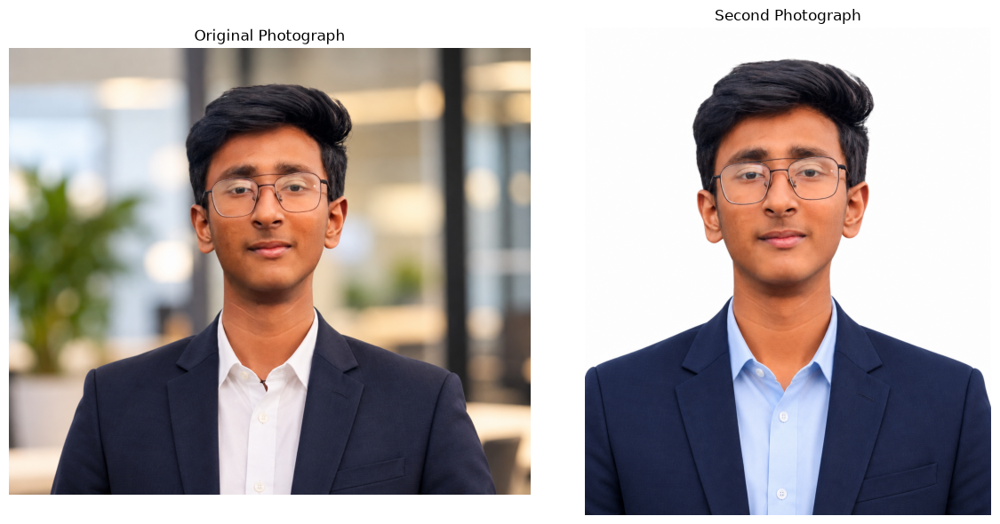

Original image dimensions: (1161, 1354, 3)
Second image dimensions: (1374, 1145, 3)

Both photographs loaded successfully!


In [6]:
# ============================================
# Step 3: Load and Display Original Photographs
# ============================================

import os
import cv2
import matplotlib.pyplot as plt

# Define image paths
image_path1 = os.path.join("data", "images", "original_photo.png")
image_path2 = os.path.join("data", "images", "second_photo.png")

# Load the photographs
original_image = cv2.imread(image_path1)
second_image = cv2.imread(image_path2)

# Check whether images loaded successfully
if original_image is None:
    raise FileNotFoundError(f"Image not found: {image_path1}")

if second_image is None:
    raise FileNotFoundError(f"Image not found: {image_path2}")

# Convert BGR images to RGB for correct display
original_rgb = cv2.cvtColor(original_image, cv2.COLOR_BGR2RGB)
second_rgb = cv2.cvtColor(second_image, cv2.COLOR_BGR2RGB)

# Display both photographs
plt.figure(figsize=(12, 6))

plt.subplot(1, 2, 1)
plt.imshow(original_rgb)
plt.title("Original Photograph")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(second_rgb)
plt.title("Second Photograph")
plt.axis("off")

plt.tight_layout()
plt.show()

# Display image information
print("Original image dimensions:", original_image.shape)
print("Second image dimensions:", second_image.shape)
print("\nBoth photographs loaded successfully!")

# UNIT 3: IMAGE RESTORATION AND SEGMENTATION

## Experiment 1: Adding Gaussian Noise to an Image

### Aim
To introduce Gaussian noise into an original photograph and study its effect on image quality.

### Theory
Gaussian noise is random noise that follows a Gaussian (normal) probability distribution. It introduces random variations in pixel intensity and can reduce the visual quality of an image.

In this experiment, we will add Gaussian noise to the original photograph and compare the noisy image with the original image.

### Procedure
1. Load the original photograph.
2. Generate random Gaussian noise.
3. Add the noise to the original image.
4. Display the original and noisy images side by side.
5. Save the noisy image for subsequent experiments.

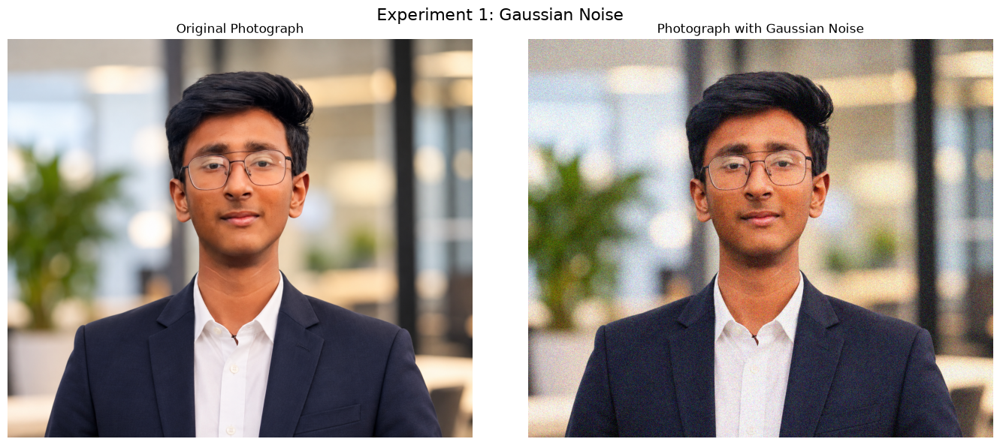

EXPERIMENT 1: GAUSSIAN NOISE
----------------------------------------
Image dimensions: (1161, 1354, 3)
Noise mean: 0
Noise standard deviation: 25
Saved output: outputs/unit3/01_gaussian_noise.png
Gaussian noise added successfully!


In [17]:
import os
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Step 1: Define image paths
image_path = "data/images/original_photo.png"
output_path = "outputs/unit3/01_gaussian_noise.png"

# Step 2: Create the output directory if it doesn't exist
os.makedirs("outputs/unit3", exist_ok=True)

# Step 3: Load the original photograph
original_image = cv2.imread(image_path)

if original_image is None:
    raise FileNotFoundError(
        f"Image not found: {image_path}. Check the image path and filename."
    )

# Step 4: Set parameters for Gaussian noise
np.random.seed(42)
mean = 0
standard_deviation = 25

# Step 5: Generate Gaussian noise
gaussian_noise = np.random.normal(
    mean,
    standard_deviation,
    original_image.shape
)

# Step 6: Add noise to the original image
noisy_image = original_image.astype(np.float32) + gaussian_noise

# Keep pixel values within the valid range of 0-255
noisy_image = np.clip(noisy_image, 0, 255).astype(np.uint8)

# Step 7: Save the noisy image
cv2.imwrite(output_path, noisy_image)

# Step 8: Convert images from BGR to RGB for correct display
original_rgb = cv2.cvtColor(original_image, cv2.COLOR_BGR2RGB)
noisy_rgb = cv2.cvtColor(noisy_image, cv2.COLOR_BGR2RGB)

# Step 9: Display the images side by side
plt.figure(figsize=(14, 6))

plt.subplot(1, 2, 1)
plt.imshow(original_rgb)
plt.title("Original Photograph")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(noisy_rgb)
plt.title("Photograph with Gaussian Noise")
plt.axis("off")

plt.suptitle("Experiment 1: Gaussian Noise", fontsize=16)
plt.tight_layout()
plt.show()

# Step 10: Display experiment details
print("EXPERIMENT 1: GAUSSIAN NOISE")
print("-" * 40)
print("Image dimensions:", original_image.shape)
print("Noise mean:", mean)
print("Noise standard deviation:", standard_deviation)
print("Saved output:", output_path)
print("Gaussian noise added successfully!")

### Observation

Gaussian noise introduces random variations in the pixel intensities of the original photograph. The noisy image appears grainier than the original, and some fine details may become less clear. The effect depends on the selected noise standard deviation.

### Result

Gaussian noise was successfully added to the original photograph. The original and noisy images were displayed for visual comparison, and the noisy image was saved for subsequent image restoration experiments.

## Experiment 2: Adding Salt-and-Pepper Noise

### Aim
To introduce salt-and-pepper noise into the original photograph and observe its effect on image quality.

### Theory
Salt-and-pepper noise is a type of impulse noise in which random pixels are replaced with either black pixels (pepper) or white pixels (salt). It creates scattered black and white dots across an image.

This experiment introduces salt-and-pepper noise into the original photograph so that the noisy image can be compared with the original image.

### Procedure
1. Load the original photograph.
2. Generate random pixel positions.
3. Replace selected pixels with black or white values.
4. Display the original and noisy images side by side.
5. Save the noisy image for subsequent image restoration experiments.

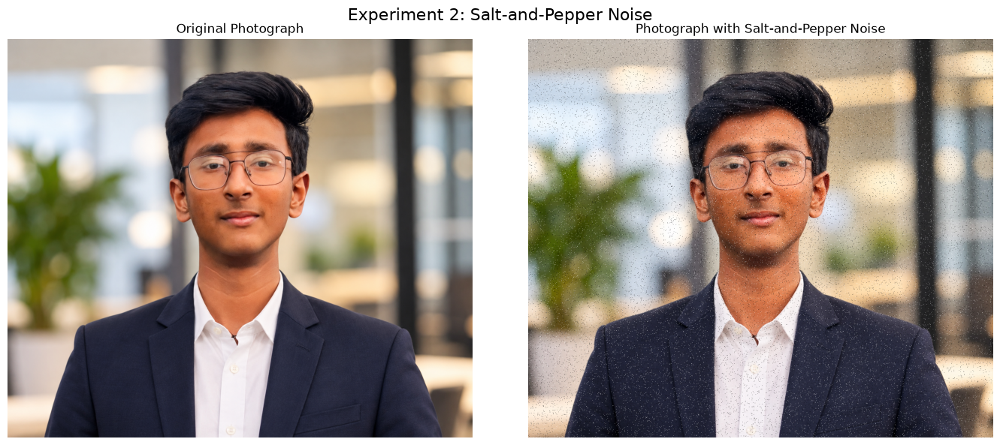

EXPERIMENT 2: SALT-AND-PEPPER NOISE
---------------------------------------------
Image dimensions: (1161, 1354, 3)
Noise percentage: 3.0 %
Approximate noisy pixels: 47159
Saved output: outputs/unit3/02_salt_pepper_noise.png
Salt-and-pepper noise added successfully!


In [21]:
import os
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Step 1: Define the image paths
image_path = "data/images/original_photo.png"
output_path = "outputs/unit3/02_salt_pepper_noise.png"

# Step 2: Create the output directory
os.makedirs("outputs/unit3", exist_ok=True)

# Step 3: Load the original photograph
original_image = cv2.imread(image_path)

if original_image is None:
    raise FileNotFoundError(f"Image not found: {image_path}")

# Step 4: Create a copy of the original image
noisy_image = original_image.copy()

# Step 5: Set the noise percentage
noise_percentage = 0.03
np.random.seed(42)

height, width = original_image.shape[:2]
total_pixels = height * width
number_of_noisy_pixels = int(total_pixels * noise_percentage)

# Step 6: Add white pixels (salt)
number_of_salt_pixels = number_of_noisy_pixels // 2

salt_rows = np.random.randint(0, height, number_of_salt_pixels)
salt_cols = np.random.randint(0, width, number_of_salt_pixels)

noisy_image[salt_rows, salt_cols] = [255, 255, 255]

# Step 7: Add black pixels (pepper)
number_of_pepper_pixels = number_of_noisy_pixels - number_of_salt_pixels

pepper_rows = np.random.randint(0, height, number_of_pepper_pixels)
pepper_cols = np.random.randint(0, width, number_of_pepper_pixels)

noisy_image[pepper_rows, pepper_cols] = [0, 0, 0]

# Step 8: Save the noisy image
cv2.imwrite(output_path, noisy_image)

# Step 9: Convert images from BGR to RGB
original_rgb = cv2.cvtColor(original_image, cv2.COLOR_BGR2RGB)
noisy_rgb = cv2.cvtColor(noisy_image, cv2.COLOR_BGR2RGB)

# Step 10: Display the images
plt.figure(figsize=(14, 6))

plt.subplot(1, 2, 1)
plt.imshow(original_rgb)
plt.title("Original Photograph")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(noisy_rgb)
plt.title("Photograph with Salt-and-Pepper Noise")
plt.axis("off")

plt.suptitle("Experiment 2: Salt-and-Pepper Noise", fontsize=16)
plt.tight_layout()
plt.show()

# Step 11: Display experiment details
print("EXPERIMENT 2: SALT-AND-PEPPER NOISE")
print("-" * 45)
print("Image dimensions:", original_image.shape)
print("Noise percentage:", noise_percentage * 100, "%")
print("Approximate noisy pixels:", number_of_noisy_pixels)
print("Saved output:", output_path)
print("Salt-and-pepper noise added successfully!")

### Observation

Salt-and-pepper noise introduces randomly distributed black and white pixels into the original photograph. These pixels create visible disturbances and may obscure some image details.

### Result

Salt-and-pepper noise was successfully added to the original photograph. The noisy image was displayed and saved for subsequent image restoration experiments.

## Experiment 3: Image Restoration Using Gaussian and Median Filters

### Aim
To reduce Gaussian noise and salt-and-pepper noise using Gaussian and median filtering techniques and compare their performance.

### Theory
Image restoration is the process of improving a degraded image by reducing noise while preserving important image details.

**Gaussian Filtering:** Gaussian filtering smooths an image by applying a Gaussian-weighted average to neighboring pixels. It is commonly used to reduce Gaussian noise, although it can blur edges and fine details.

**Median Filtering:** Median filtering replaces each pixel with the median of the pixel values in its neighborhood. It is particularly effective at removing salt-and-pepper noise while preserving edges better than simple averaging filters.

In this experiment, both filters will be applied to the noisy photographs, and their results will be compared visually.

### Procedure
1. Load the original photograph and the noisy images generated in the previous experiments.
2. Apply Gaussian filtering to the Gaussian-noisy image.
3. Apply median filtering to the salt-and-pepper-noisy image.
4. Display the original, noisy, and restored images for comparison.
5. Save the restored images for further analysis.

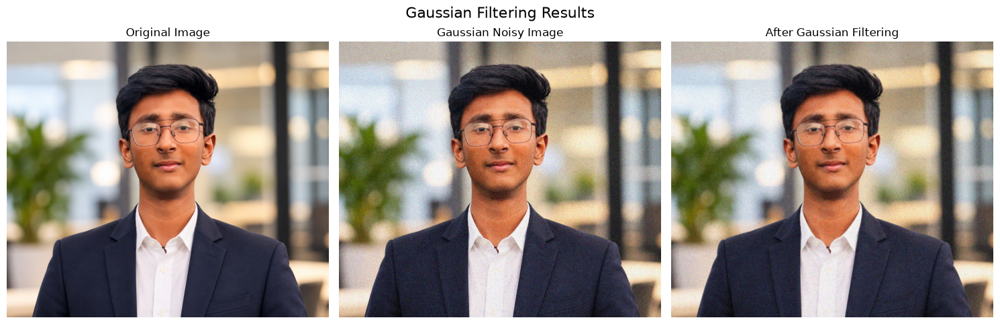

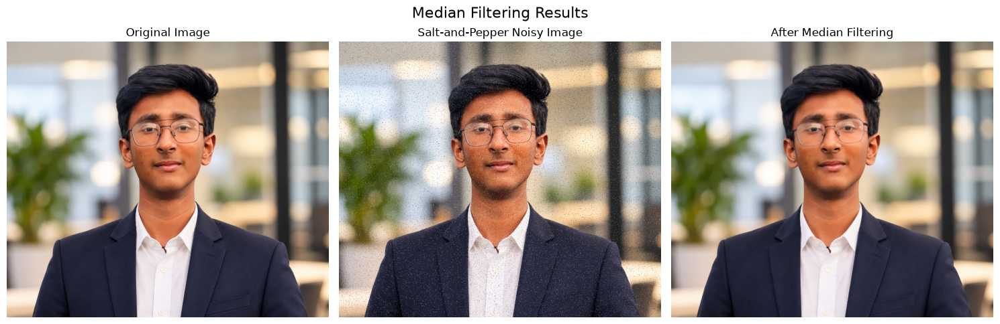

EXPERIMENT 3: IMAGE RESTORATION
----------------------------------------
Gaussian filter kernel size: 5 x 5
Median filter kernel size: 5 x 5
Gaussian-filtered image: outputs/unit3/03_gaussian_filtered.png
Median-filtered image: outputs/unit3/04_median_filtered.png
Image restoration completed successfully!


In [23]:
import os
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Step 1: Define image paths
original_path = "data/images/original_photo.png"
gaussian_path = "outputs/unit3/01_gaussian_noise.png"
salt_pepper_path = "outputs/unit3/02_salt_pepper_noise.png"

gaussian_restored_path = "outputs/unit3/03_gaussian_filtered.png"
median_restored_path = "outputs/unit3/04_median_filtered.png"

os.makedirs("outputs/unit3", exist_ok=True)

# Step 2: Load images
original = cv2.imread(original_path)
gaussian_noisy = cv2.imread(gaussian_path)
salt_pepper_noisy = cv2.imread(salt_pepper_path)

if original is None:
    raise FileNotFoundError(f"Original image not found: {original_path}")

if gaussian_noisy is None:
    raise FileNotFoundError(
        "Gaussian-noisy image not found. Run Experiment 1 first."
    )

if salt_pepper_noisy is None:
    raise FileNotFoundError(
        "Salt-and-pepper image not found. Run Experiment 2 first."
    )

# Step 3: Apply Gaussian filter
gaussian_filtered = cv2.GaussianBlur(
    gaussian_noisy,
    (5, 5),
    0
)

# Step 4: Apply median filter
median_filtered = cv2.medianBlur(
    salt_pepper_noisy,
    5
)

# Step 5: Save restored images
cv2.imwrite(gaussian_restored_path, gaussian_filtered)
cv2.imwrite(median_restored_path, median_filtered)

# Step 6: Convert images to RGB
original_rgb = cv2.cvtColor(original, cv2.COLOR_BGR2RGB)
gaussian_noisy_rgb = cv2.cvtColor(gaussian_noisy, cv2.COLOR_BGR2RGB)
gaussian_filtered_rgb = cv2.cvtColor(gaussian_filtered, cv2.COLOR_BGR2RGB)

salt_pepper_rgb = cv2.cvtColor(salt_pepper_noisy, cv2.COLOR_BGR2RGB)
median_filtered_rgb = cv2.cvtColor(median_filtered, cv2.COLOR_BGR2RGB)

# Step 7: Display Gaussian filtering results
plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(original_rgb)
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(gaussian_noisy_rgb)
plt.title("Gaussian Noisy Image")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(gaussian_filtered_rgb)
plt.title("After Gaussian Filtering")
plt.axis("off")

plt.suptitle("Gaussian Filtering Results", fontsize=16)
plt.tight_layout()
plt.show()

# Step 8: Display median filtering results
plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(original_rgb)
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(salt_pepper_rgb)
plt.title("Salt-and-Pepper Noisy Image")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(median_filtered_rgb)
plt.title("After Median Filtering")
plt.axis("off")

plt.suptitle("Median Filtering Results", fontsize=16)
plt.tight_layout()
plt.show()

# Step 9: Display experiment details
print("EXPERIMENT 3: IMAGE RESTORATION")
print("-" * 40)
print("Gaussian filter kernel size: 5 x 5")
print("Median filter kernel size: 5 x 5")
print("Gaussian-filtered image:", gaussian_restored_path)
print("Median-filtered image:", median_restored_path)
print("Image restoration completed successfully!")

### Observation

Gaussian filtering reduces the random variations introduced by Gaussian noise, but it may also blur fine details. Median filtering removes many of the black and white pixels caused by salt-and-pepper noise while generally preserving edges more effectively.

The effectiveness of each filter depends on the noise level and the selected kernel size.

### Result

Gaussian and median filters were successfully applied to the noisy photographs. The original, noisy, and restored images were displayed and compared. The restored images were saved for further analysis.

## Experiment 4: Image Quality Evaluation Using PSNR and SSIM

### Aim
To evaluate the quality of restored images using Peak Signal-to-Noise Ratio (PSNR) and Structural Similarity Index (SSIM).

### Theory

**PSNR (Peak Signal-to-Noise Ratio):** PSNR measures the difference between an original image and a processed image using the mean squared error. A higher PSNR generally indicates less pixel-level distortion.

**SSIM (Structural Similarity Index):** SSIM compares the structural similarity between two images by considering luminance, contrast, and structure. Its value is typically between -1 and 1, with values closer to 1 indicating greater similarity.

In this experiment, PSNR and SSIM will be calculated for the noisy and restored images by comparing them with the original photograph.

### Procedure
1. Load the original, noisy, and restored images.
2. Calculate PSNR for each image compared with the original.
3. Calculate SSIM for each image compared with the original.
4. Display the evaluation metrics in a table.
5. Compare the results to assess the effectiveness of the filters.

In [25]:
%pip install pandas

   ---------------------------------------- 0.0/10.7 MB ? eta -:--:--
   -- ------------------------------------- 0.8/10.7 MB 5.6 MB/s eta 0:00:02
   ---------- ----------------------------- 2.9/10.7 MB 8.4 MB/s eta 0:00:01
   ------------- -------------------------- 3.7/10.7 MB 6.8 MB/s eta 0:00:02
   -------------- ------------------------- 3.9/10.7 MB 5.6 MB/s eta 0:00:02
   ---------------- ----------------------- 4.5/10.7 MB 4.7 MB/s eta 0:00:02
   ------------------ --------------------- 5.0/10.7 MB 4.1 MB/s eta 0:00:02
   -------------------- ------------------- 5.5/10.7 MB 3.8 MB/s eta 0:00:02
   ---------------------- ----------------- 6.0/10.7 MB 3.6 MB/s eta 0:00:02
   ------------------------ --------------- 6.6/10.7 MB 3.5 MB/s eta 0:00:02
   ------------------------- -------------- 6.8/10.7 MB 3.5 MB/s eta 0:00:02
   -------------------------- ------------- 7.1/10.7 MB 3.3 MB/s eta 0:00:02
   --------------------------- ------------ 7.3/10.7 MB 3.1 MB/s eta 0:00:02
   ---

In [27]:
import cv2
import pandas as pd
from skimage.metrics import peak_signal_noise_ratio, structural_similarity

# Step 1: Load the original image
original = cv2.imread("data/images/original_photo.png")

# Step 2: Load noisy and restored images
images = {
    "Gaussian Noisy": "outputs/unit3/01_gaussian_noise.png",
    "Gaussian Filtered": "outputs/unit3/03_gaussian_filtered.png",
    "Salt-and-Pepper Noisy": "outputs/unit3/02_salt_pepper_noise.png",
    "Median Filtered": "outputs/unit3/04_median_filtered.png"
}

if original is None:
    raise FileNotFoundError("Original photograph not found.")

results = []

# Step 3: Calculate PSNR and SSIM
for image_name, image_path in images.items():
    processed = cv2.imread(image_path)

    if processed is None:
        raise FileNotFoundError(f"Image not found: {image_path}")

    if processed.shape != original.shape:
        raise ValueError(f"Image dimensions do not match: {image_name}")

    psnr_value = peak_signal_noise_ratio(
        original,
        processed,
        data_range=255
    )

    ssim_value = structural_similarity(
        original,
        processed,
        channel_axis=2,
        data_range=255
    )

    results.append({
        "Image": image_name,
        "PSNR (dB)": round(psnr_value, 2),
        "SSIM": round(ssim_value, 4)
    })

# Step 4: Display results
results_df = pd.DataFrame(results)

print("EXPERIMENT 4: IMAGE QUALITY EVALUATION")
print("-" * 50)
display(results_df)

EXPERIMENT 4: IMAGE QUALITY EVALUATION
--------------------------------------------------


,Image,PSNR (dB),SSIM
0,Gaussian Noisy,20.57,0.1623
1,Gaussian Filtered,30.80,0.6910
2,Salt-and-Pepper Noisy,20.05,0.4204
3,Median Filtered,39.12,0.9621


### Observation

The Gaussian-noisy image achieved a PSNR of 20.57 dB and an SSIM of 0.1623. After Gaussian filtering, the PSNR increased to 30.80 dB and the SSIM increased to 0.6910.

The salt-and-pepper-noisy image achieved a PSNR of 20.05 dB and an SSIM of 0.4204. After median filtering, the PSNR increased to 39.12 dB and the SSIM increased to 0.9621.

The results indicate that both filters improved image quality. Median filtering performed better for the salt-and-pepper-noisy image, producing higher PSNR and SSIM values.

### Result

PSNR and SSIM were successfully calculated for the noisy and restored images. The quantitative evaluation demonstrated that image filtering improved similarity to the original photograph. Among the evaluated results, median filtering achieved the highest PSNR and SSIM values.

## Experiment 5: Image Segmentation Using Thresholding

### Aim
To segment an image using binary thresholding, adaptive thresholding, and Otsu's thresholding.

### Theory

Image segmentation divides an image into meaningful regions to simplify its representation and analysis.

**Binary Thresholding:** Assigns pixels to either black or white depending on whether their intensity is below or above a specified threshold.

**Adaptive Thresholding:** Calculates a local threshold for different image regions, making it useful when illumination varies across the image.

**Otsu's Thresholding:** Automatically determines a threshold based on the image's grayscale intensity distribution.

### Procedure
1. Load the original photograph.
2. Convert the photograph to grayscale.
3. Apply binary thresholding.
4. Apply adaptive thresholding.
5. Apply Otsu's thresholding.
6. Display and save the segmentation results.

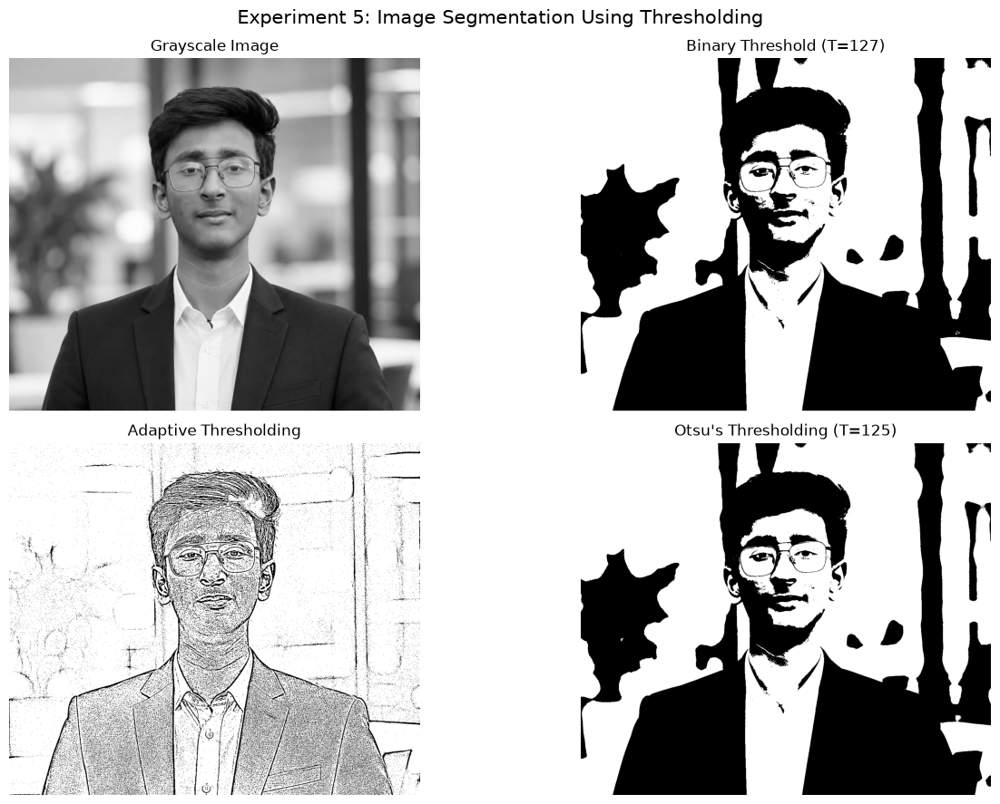

EXPERIMENT 5: THRESHOLDING
----------------------------------------
Original image dimensions: (1161, 1354, 3)
Binary threshold value: 127
Otsu's automatically calculated threshold: 125.0
Saved outputs in: outputs/unit3
Thresholding completed successfully!


In [28]:
import os
import cv2
import matplotlib.pyplot as plt

# Step 1: Define image paths
image_path = "data/images/original_photo.png"
output_dir = "outputs/unit3"

os.makedirs(output_dir, exist_ok=True)

# Step 2: Load the original photograph
original = cv2.imread(image_path)

if original is None:
    raise FileNotFoundError(f"Image not found: {image_path}")

# Step 3: Convert the image to grayscale
gray = cv2.cvtColor(original, cv2.COLOR_BGR2GRAY)

# Step 4: Apply binary thresholding
threshold_value = 127

_, binary_threshold = cv2.threshold(
    gray,
    threshold_value,
    255,
    cv2.THRESH_BINARY
)

# Step 5: Apply adaptive thresholding
adaptive_threshold = cv2.adaptiveThreshold(
    gray,
    255,
    cv2.ADAPTIVE_THRESH_GAUSSIAN_C,
    cv2.THRESH_BINARY,
    11,
    2
)

# Step 6: Apply Otsu's thresholding
otsu_value, otsu_threshold = cv2.threshold(
    gray,
    0,
    255,
    cv2.THRESH_BINARY + cv2.THRESH_OTSU
)

# Step 7: Save the results
cv2.imwrite(f"{output_dir}/05_grayscale.png", gray)
cv2.imwrite(f"{output_dir}/06_binary_threshold.png", binary_threshold)
cv2.imwrite(f"{output_dir}/07_adaptive_threshold.png", adaptive_threshold)
cv2.imwrite(f"{output_dir}/08_otsu_threshold.png", otsu_threshold)

# Step 8: Display the results
plt.figure(figsize=(14, 9))

plt.subplot(2, 2, 1)
plt.imshow(gray, cmap="gray")
plt.title("Grayscale Image")
plt.axis("off")

plt.subplot(2, 2, 2)
plt.imshow(binary_threshold, cmap="gray")
plt.title(f"Binary Threshold (T={threshold_value})")
plt.axis("off")

plt.subplot(2, 2, 3)
plt.imshow(adaptive_threshold, cmap="gray")
plt.title("Adaptive Thresholding")
plt.axis("off")

plt.subplot(2, 2, 4)
plt.imshow(otsu_threshold, cmap="gray")
plt.title(f"Otsu's Thresholding (T={otsu_value:.0f})")
plt.axis("off")

plt.suptitle("Experiment 5: Image Segmentation Using Thresholding", fontsize=15)
plt.tight_layout()
plt.show()

# Step 9: Display experiment details
print("EXPERIMENT 5: THRESHOLDING")
print("-" * 40)
print("Original image dimensions:", original.shape)
print("Binary threshold value:", threshold_value)
print("Otsu's automatically calculated threshold:", otsu_value)
print("Saved outputs in:", output_dir)
print("Thresholding completed successfully!")

### Observation

Binary thresholding separates pixels into black and white regions using a fixed threshold value. Adaptive thresholding calculates local thresholds and can handle variations in illumination. Otsu's method automatically selects a threshold based on the grayscale intensity distribution.

The resulting segmentation quality depends on the image's lighting, contrast, and intensity distribution.

### Result

Binary, adaptive, and Otsu's thresholding were successfully applied to the original photograph. The grayscale image and segmentation results were displayed and saved for comparison.

## Experiment 6: Image Segmentation Using Morphological Operations

### Aim
To perform erosion, dilation, opening, and closing on a binary image and observe their effects.

### Theory

Morphological operations are image-processing techniques that modify the shape and structure of foreground regions using a structuring element, also called a kernel.

**Erosion:** Removes pixels from the boundaries of foreground regions, causing white regions to shrink.

**Dilation:** Adds pixels to the boundaries of foreground regions, causing white regions to expand.

**Opening:** Applies erosion followed by dilation. It can remove small foreground objects and noise.

**Closing:** Applies dilation followed by erosion. It can fill small holes and connect nearby foreground regions.

### Procedure
1. Load the original photograph.
2. Convert the photograph to grayscale.
3. Apply binary thresholding to create a binary image.
4. Define a structuring element.
5. Apply erosion, dilation, opening, and closing.
6. Display and save the results for comparison.

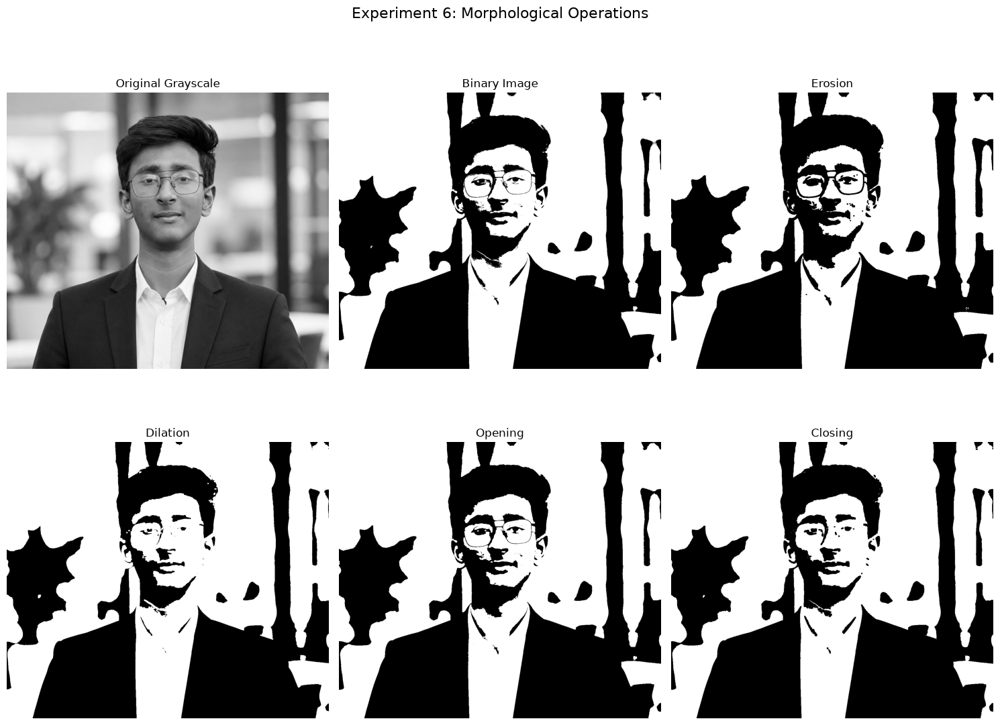

EXPERIMENT 6: MORPHOLOGICAL OPERATIONS
---------------------------------------------
Structuring element: 5 x 5 rectangular kernel
Operations: Erosion, Dilation, Opening, Closing
Saved outputs in: outputs/unit3
Morphological operations completed successfully!


In [29]:
import os
import cv2
import matplotlib.pyplot as plt

# Step 1: Define paths
image_path = "data/images/original_photo.png"
output_dir = "outputs/unit3"

os.makedirs(output_dir, exist_ok=True)

# Step 2: Load the original photograph
original = cv2.imread(image_path)

if original is None:
    raise FileNotFoundError(f"Image not found: {image_path}")

# Step 3: Convert the image to grayscale
gray = cv2.cvtColor(original, cv2.COLOR_BGR2GRAY)

# Step 4: Create a binary image using Otsu's thresholding
_, binary = cv2.threshold(
    gray,
    0,
    255,
    cv2.THRESH_BINARY + cv2.THRESH_OTSU
)

# Step 5: Define a 5x5 structuring element
kernel = cv2.getStructuringElement(
    cv2.MORPH_RECT,
    (5, 5)
)

# Step 6: Apply morphological operations
erosion = cv2.erode(binary, kernel, iterations=1)
dilation = cv2.dilate(binary, kernel, iterations=1)
opening = cv2.morphologyEx(binary, cv2.MORPH_OPEN, kernel)
closing = cv2.morphologyEx(binary, cv2.MORPH_CLOSE, kernel)

# Step 7: Save all results
cv2.imwrite(f"{output_dir}/09_morphology_binary.png", binary)
cv2.imwrite(f"{output_dir}/10_erosion.png", erosion)
cv2.imwrite(f"{output_dir}/11_dilation.png", dilation)
cv2.imwrite(f"{output_dir}/12_opening.png", opening)
cv2.imwrite(f"{output_dir}/13_closing.png", closing)

# Step 8: Display the results
images = [
    ("Original Grayscale", gray),
    ("Binary Image", binary),
    ("Erosion", erosion),
    ("Dilation", dilation),
    ("Opening", opening),
    ("Closing", closing)
]

plt.figure(figsize=(15, 12))

for index, (title, image) in enumerate(images, start=1):
    plt.subplot(2, 3, index)
    plt.imshow(image, cmap="gray")
    plt.title(title)
    plt.axis("off")

plt.suptitle(
    "Experiment 6: Morphological Operations",
    fontsize=16
)
plt.tight_layout()
plt.show()

# Step 9: Display experiment details
print("EXPERIMENT 6: MORPHOLOGICAL OPERATIONS")
print("-" * 45)
print("Structuring element: 5 x 5 rectangular kernel")
print("Operations: Erosion, Dilation, Opening, Closing")
print("Saved outputs in:", output_dir)
print("Morphological operations completed successfully!")

### Observation

Erosion reduced the size of white foreground regions, while dilation expanded them. Opening helped remove small foreground regions and noise. Closing helped fill small holes and gaps in the binary image.

The observed effects depended on the binary image and the selected structuring element.

### Result

Erosion, dilation, opening, and closing were successfully applied to the thresholded image using OpenCV. The resulting images were displayed and saved for comparison.

## Experiment 7: Edge Detection Using the Canny Algorithm

### Aim
To detect edges in the original photograph using the Canny edge detection algorithm.

### Theory
Edge detection is an image-processing technique used to identify boundaries and regions where image intensity changes significantly.

The Canny edge detection algorithm identifies edges through several stages, including noise reduction, gradient calculation, non-maximum suppression, and hysteresis thresholding.

It uses two threshold values to distinguish strong edges from weak edges and suppress irrelevant responses.

### Procedure
1. Load the original photograph.
2. Convert the photograph to grayscale.
3. Apply Gaussian blurring to reduce noise.
4. Apply the Canny edge detection algorithm.
5. Display the original, grayscale, and edge-detected images.
6. Save the resulting edge image.

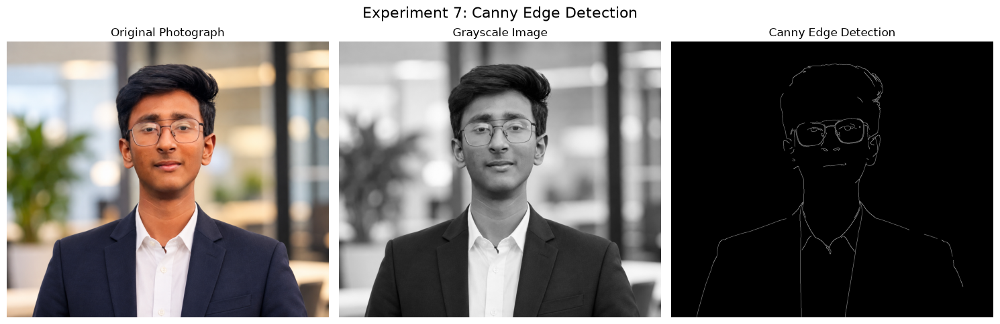

EXPERIMENT 7: CANNY EDGE DETECTION
----------------------------------------
Image dimensions: (1161, 1354, 3)
Lower threshold: 100
Upper threshold: 200
Saved edge image: outputs/unit3/14_canny_edges.png
Canny edge detection completed successfully!


In [30]:
import os
import cv2
import matplotlib.pyplot as plt

# Step 1: Define image paths
image_path = "data/images/original_photo.png"
output_dir = "outputs/unit3"
output_path = f"{output_dir}/14_canny_edges.png"

os.makedirs(output_dir, exist_ok=True)

# Step 2: Load the original photograph
original = cv2.imread(image_path)

if original is None:
    raise FileNotFoundError(f"Image not found: {image_path}")

# Step 3: Convert the image to grayscale
gray = cv2.cvtColor(original, cv2.COLOR_BGR2GRAY)

# Step 4: Reduce noise using Gaussian blurring
blurred = cv2.GaussianBlur(gray, (5, 5), 0)

# Step 5: Apply Canny edge detection
lower_threshold = 100
upper_threshold = 200

edges = cv2.Canny(
    blurred,
    lower_threshold,
    upper_threshold
)

# Step 6: Save the edge image
cv2.imwrite(output_path, edges)

# Step 7: Display the results
plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(cv2.cvtColor(original, cv2.COLOR_BGR2RGB))
plt.title("Original Photograph")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(gray, cmap="gray")
plt.title("Grayscale Image")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(edges, cmap="gray")
plt.title("Canny Edge Detection")
plt.axis("off")

plt.suptitle(
    "Experiment 7: Canny Edge Detection",
    fontsize=16
)

plt.tight_layout()
plt.show()

# Step 8: Display experiment details
print("EXPERIMENT 7: CANNY EDGE DETECTION")
print("-" * 40)
print("Image dimensions:", original.shape)
print("Lower threshold:", lower_threshold)
print("Upper threshold:", upper_threshold)
print("Saved edge image:", output_path)
print("Canny edge detection completed successfully!")

### Observation

Canny edge detection highlighted intensity boundaries in the photograph, including facial features, glasses, hair, clothing, and background objects. Gaussian blurring helped reduce noise before edge detection.

The detected edges depend on the selected lower and upper threshold values.

### Result

The Canny edge detection algorithm was successfully applied to the original photograph. The original, grayscale, and edge-detected images were displayed, and the resulting edge image was saved.

## Experiment 8: Image Segmentation Using the Watershed Algorithm

### Aim
To perform image segmentation using the Watershed algorithm in OpenCV.

### Theory
The Watershed algorithm is a region-based image segmentation technique that separates an image into different regions. It treats image intensity variations as a topographic surface, where regions are separated by boundaries called watershed lines.

The algorithm uses markers to identify foreground, background, and unknown regions. These markers guide the segmentation process.

In OpenCV, the Watershed algorithm is commonly applied to a color image after preparing a binary mask and identifying foreground and background regions.

### Procedure
1. Load the original photograph.
2. Apply Gaussian blurring to reduce noise.
3. Convert the image to grayscale and create a binary image using Otsu's thresholding.
4. Apply morphological operations to identify foreground and background regions.
5. Create markers for the Watershed algorithm.
6. Apply the Watershed algorithm.
7. Display and save the segmented image.

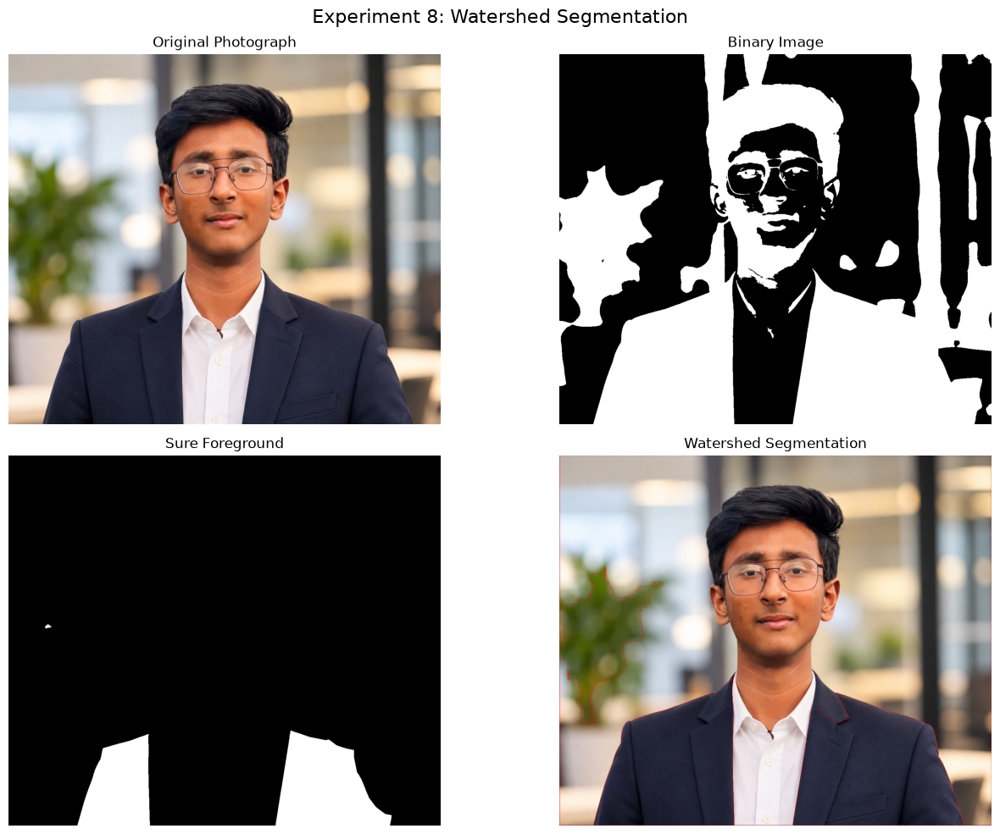

EXPERIMENT 8: WATERSHED SEGMENTATION
---------------------------------------------
Image dimensions: (1161, 1354, 3)
Connected foreground components: 3
Saved outputs in: outputs/unit3
Watershed segmentation completed successfully!


In [31]:
import os
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Step 1: Define image paths
image_path = "data/images/original_photo.png"
output_dir = "outputs/unit3"

os.makedirs(output_dir, exist_ok=True)

# Step 2: Load the original photograph
original = cv2.imread(image_path)

if original is None:
    raise FileNotFoundError(f"Image not found: {image_path}")

# Step 3: Reduce noise
blurred = cv2.GaussianBlur(original, (5, 5), 0)

# Step 4: Convert to grayscale
gray = cv2.cvtColor(blurred, cv2.COLOR_BGR2GRAY)

# Step 5: Create a binary image using Otsu's thresholding
_, binary = cv2.threshold(
    gray,
    0,
    255,
    cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU
)

# Step 6: Remove small noise using morphological opening
kernel = np.ones((3, 3), np.uint8)
opening = cv2.morphologyEx(
    binary,
    cv2.MORPH_OPEN,
    kernel,
    iterations=2
)

# Step 7: Identify the background region
sure_background = cv2.dilate(
    opening,
    kernel,
    iterations=3
)

# Step 8: Identify the foreground region using a distance transform
distance_transform = cv2.distanceTransform(
    opening,
    cv2.DIST_L2,
    5
)

_, sure_foreground = cv2.threshold(
    distance_transform,
    0.4 * distance_transform.max(),
    255,
    0
)

sure_foreground = np.uint8(sure_foreground)

# Step 9: Identify unknown regions
unknown = cv2.subtract(
    sure_background,
    sure_foreground
)

# Step 10: Create markers
number_of_markers, markers = cv2.connectedComponents(
    sure_foreground
)

markers = markers + 1
markers[unknown == 255] = 0

# Step 11: Apply the Watershed algorithm
watershed_markers = cv2.watershed(
    original.copy(),
    markers
)

# Step 12: Highlight watershed boundaries in red
segmented = original.copy()
segmented[watershed_markers == -1] = [0, 0, 255]

# Step 13: Save outputs
cv2.imwrite(f"{output_dir}/15_watershed_binary.png", binary)
cv2.imwrite(f"{output_dir}/16_watershed_foreground.png", sure_foreground)
cv2.imwrite(f"{output_dir}/17_watershed_segmentation.png", segmented)

# Step 14: Convert images to RGB for display
original_rgb = cv2.cvtColor(original, cv2.COLOR_BGR2RGB)
binary_rgb = cv2.cvtColor(binary, cv2.COLOR_GRAY2RGB)
foreground_rgb = cv2.cvtColor(sure_foreground, cv2.COLOR_GRAY2RGB)
segmented_rgb = cv2.cvtColor(segmented, cv2.COLOR_BGR2RGB)

# Step 15: Display the results
plt.figure(figsize=(14, 10))

plt.subplot(2, 2, 1)
plt.imshow(original_rgb)
plt.title("Original Photograph")
plt.axis("off")

plt.subplot(2, 2, 2)
plt.imshow(binary_rgb)
plt.title("Binary Image")
plt.axis("off")

plt.subplot(2, 2, 3)
plt.imshow(foreground_rgb)
plt.title("Sure Foreground")
plt.axis("off")

plt.subplot(2, 2, 4)
plt.imshow(segmented_rgb)
plt.title("Watershed Segmentation")
plt.axis("off")

plt.suptitle(
    "Experiment 8: Watershed Segmentation",
    fontsize=16
)

plt.tight_layout()
plt.show()

# Step 16: Display experiment details
print("EXPERIMENT 8: WATERSHED SEGMENTATION")
print("-" * 45)
print("Image dimensions:", original.shape)
print("Connected foreground components:", number_of_markers - 1)
print("Saved outputs in:", output_dir)
print("Watershed segmentation completed successfully!")

### Observation

The Watershed algorithm divided the image into regions using foreground and background markers. The segmentation boundaries were highlighted in red in the final image.

The sure foreground image contained only a few white regions, indicating that the foreground markers were restrictive. The complex background and variations in image intensity affected the segmentation quality.

### Result

The Watershed segmentation algorithm was successfully applied using OpenCV. The binary image, estimated foreground, and final segmented image were displayed and saved. The experiment demonstrated how marker selection affects the quality of Watershed segmentation.

# UNIT 4: FEATURE EXTRACTION AND MATCHING

## Experiment 9: Feature Extraction Using Histogram of Oriented Gradients (HOG)

### Aim
To extract shape and edge features from a photograph using the Histogram of Oriented Gradients (HOG) descriptor.

### Theory
Histogram of Oriented Gradients (HOG) is a feature descriptor used in computer vision to represent the shape and appearance of objects.

HOG calculates image gradients and summarizes their orientations within local image regions. The resulting descriptor captures information about object boundaries, contours, and shapes.

HOG features are commonly used in object detection and image classification tasks.

### Procedure
1. Load the original photograph.
2. Resize the image to a fixed size.
3. Convert the image to grayscale.
4. Configure the HOG descriptor.
5. Extract the HOG feature vector.
6. Visualize the HOG features.
7. Display and save the HOG visualization.

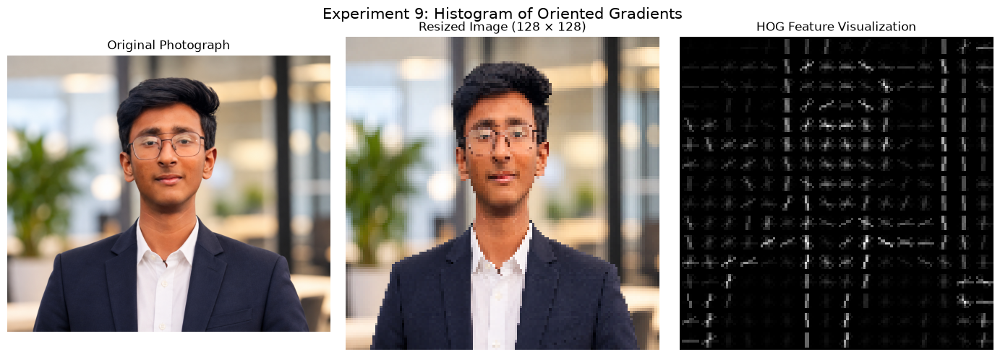

EXPERIMENT 9: HOG FEATURE EXTRACTION
---------------------------------------------
Original image dimensions: (1161, 1354, 3)
Resized image dimensions: (128, 128, 3)
HOG feature vector length: 8100
Orientations: 9
Pixels per cell: 8 x 8
Cells per block: 2 x 2
Saved HOG visualization: outputs/unit4/01_hog_visualization.png
HOG feature extraction completed successfully!


In [32]:
import os
import cv2
import numpy as np
import matplotlib.pyplot as plt
from skimage.feature import hog

# Step 1: Define paths
image_path = "data/images/original_photo.png"
output_dir = "outputs/unit4"

os.makedirs(output_dir, exist_ok=True)

# Step 2: Load the original photograph
original = cv2.imread(image_path)

if original is None:
    raise FileNotFoundError(f"Image not found: {image_path}")

# Step 3: Resize the image
resized = cv2.resize(original, (128, 128))

# Step 4: Convert the image to grayscale
gray = cv2.cvtColor(resized, cv2.COLOR_BGR2GRAY)

# Step 5: Extract HOG features and generate visualization
hog_features, hog_image = hog(
    gray,
    orientations=9,
    pixels_per_cell=(8, 8),
    cells_per_block=(2, 2),
    visualize=True,
    block_norm="L2-Hys"
)

# Step 6: Save the HOG visualization
hog_output_path = f"{output_dir}/01_hog_visualization.png"

# Normalize the visualization for saving
hog_display = cv2.normalize(
    hog_image,
    None,
    0,
    255,
    cv2.NORM_MINMAX
).astype(np.uint8)

cv2.imwrite(hog_output_path, hog_display)

# Step 7: Display the results
original_rgb = cv2.cvtColor(original, cv2.COLOR_BGR2RGB)
resized_rgb = cv2.cvtColor(resized, cv2.COLOR_BGR2RGB)

plt.figure(figsize=(14, 5))

plt.subplot(1, 3, 1)
plt.imshow(original_rgb)
plt.title("Original Photograph")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(resized_rgb)
plt.title("Resized Image (128 × 128)")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(hog_image, cmap="gray")
plt.title("HOG Feature Visualization")
plt.axis("off")

plt.suptitle(
    "Experiment 9: Histogram of Oriented Gradients",
    fontsize=15
)

plt.tight_layout()
plt.show()

# Step 8: Display experiment details
print("EXPERIMENT 9: HOG FEATURE EXTRACTION")
print("-" * 45)
print("Original image dimensions:", original.shape)
print("Resized image dimensions:", resized.shape)
print("HOG feature vector length:", len(hog_features))
print("Orientations:", 9)
print("Pixels per cell: 8 x 8")
print("Cells per block: 2 x 2")
print("Saved HOG visualization:", hog_output_path)
print("HOG feature extraction completed successfully!")

### Observation

The original photograph was resized to 128 × 128 pixels and converted to grayscale before HOG feature extraction. The HOG visualization highlighted gradients and edge orientations that represent the shape and appearance of the subject.

The HOG descriptor generated a numerical feature vector based on the selected parameters, including nine orientations, 8 × 8 pixels per cell, and 2 × 2 cells per block.

### Result

HOG feature extraction was successfully performed using the scikit-image library. The original photograph, resized image, and HOG visualization were displayed, and the visualization was saved for further analysis.

## Experiment 10: SIFT Feature Detection and Matching

### Aim
To detect distinctive keypoints and extract SIFT descriptors from two photographs, then match the features between them.

### Theory
Scale-Invariant Feature Transform (SIFT) is a feature detection and description algorithm used in computer vision. It identifies distinctive keypoints that can be matched across images despite changes in scale, rotation, and moderate changes in illumination.

SIFT detects keypoints and computes a numerical descriptor for each keypoint. These descriptors can be compared to identify corresponding features between two images.

In this experiment, SIFT features will be extracted from two photographs, and their descriptors will be matched using a feature-matching algorithm.

### Procedure
1. Load the two photographs.
2. Convert both photographs to grayscale.
3. Detect SIFT keypoints and compute descriptors.
4. Match descriptors using a Brute-Force matcher.
5. Filter matches using the Lowe ratio test.
6. Visualize the matched keypoints.
7. Display and save the matching result.

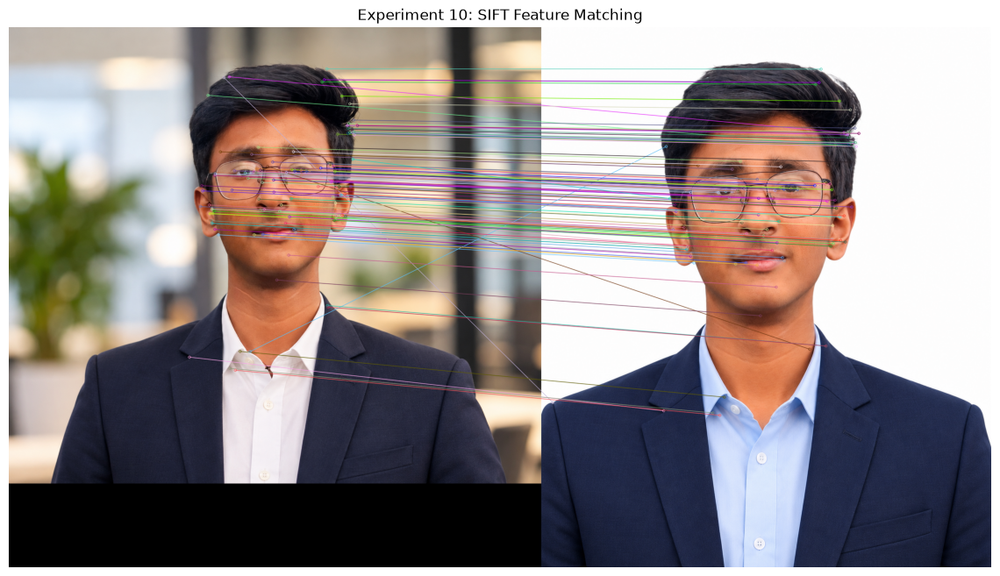

EXPERIMENT 10: SIFT FEATURE MATCHING
---------------------------------------------
Image 1 dimensions: (1161, 1354, 3)
Image 2 dimensions: (1374, 1145, 3)
Keypoints in image 1: 495
Keypoints in image 2: 558
Good matches after Lowe's ratio test: 114
Saved matching result: outputs/unit4/02_sift_feature_matching.png
SIFT feature matching completed successfully!


In [34]:
import os
import cv2
import matplotlib.pyplot as plt

# Step 1: Define image paths
image1_path = "data/images/original_photo.png"
image2_path = "data/images/second_photo.png"
output_dir = "outputs/unit4"

os.makedirs(output_dir, exist_ok=True)

# Step 2: Load both photographs
image1 = cv2.imread(image1_path)
image2 = cv2.imread(image2_path)

if image1 is None:
    raise FileNotFoundError(f"Image not found: {image1_path}")

if image2 is None:
    raise FileNotFoundError(f"Image not found: {image2_path}")

# Step 3: Convert both images to grayscale
gray1 = cv2.cvtColor(image1, cv2.COLOR_BGR2GRAY)
gray2 = cv2.cvtColor(image2, cv2.COLOR_BGR2GRAY)

# Step 4: Create the SIFT detector
sift = cv2.SIFT_create()

# Step 5: Detect keypoints and calculate descriptors
keypoints1, descriptors1 = sift.detectAndCompute(gray1, None)
keypoints2, descriptors2 = sift.detectAndCompute(gray2, None)

if descriptors1 is None or descriptors2 is None:
    raise ValueError("SIFT could not find enough features in one of the images.")

# Step 6: Match descriptors using the Brute-Force matcher
matcher = cv2.BFMatcher(cv2.NORM_L2)

matches = matcher.knnMatch(
    descriptors1,
    descriptors2,
    k=2
)

# Step 7: Apply Lowe's ratio test
good_matches = []

for pair in matches:
    if len(pair) == 2:
        first_match, second_match = pair

        if first_match.distance < 0.75 * second_match.distance:
            good_matches.append(first_match)

# Step 8: Draw the matching keypoints
matched_image = cv2.drawMatches(
    image1,
    keypoints1,
    image2,
    keypoints2,
    good_matches,
    None,
    flags=cv2.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS
)

# Step 9: Save the result
output_path = f"{output_dir}/02_sift_feature_matching.png"
cv2.imwrite(output_path, matched_image)

# Step 10: Display the results
matched_rgb = cv2.cvtColor(
    matched_image,
    cv2.COLOR_BGR2RGB
)

plt.figure(figsize=(16, 8))
plt.imshow(matched_rgb)
plt.title("Experiment 10: SIFT Feature Matching")
plt.axis("off")
plt.show()

# Step 11: Display experiment details
print("EXPERIMENT 10: SIFT FEATURE MATCHING")
print("-" * 45)
print("Image 1 dimensions:", image1.shape)
print("Image 2 dimensions:", image2.shape)
print("Keypoints in image 1:", len(keypoints1))
print("Keypoints in image 2:", len(keypoints2))
print("Good matches after Lowe's ratio test:", len(good_matches))
print("Saved matching result:", output_path)
print("SIFT feature matching completed successfully!")

### Observation

SIFT detected distinctive keypoints in both photographs and calculated descriptors for matching. The Brute-Force matcher compared the descriptors, and Lowe's ratio test filtered potentially unreliable matches.

The number and quality of matches depended on the similarity of the photographs, their backgrounds, lighting, and visible features.

### Result

SIFT keypoint detection, descriptor extraction, and feature matching were successfully performed using OpenCV. The matching visualization was displayed and saved for analysis.

## Experiment 11: Image Rotation and Resizing

### Aim
To perform image rotation and resizing using OpenCV and observe their effects on an image.

### Theory
Image transformation techniques modify the position, orientation, or dimensions of an image.

**Image Rotation:** Rotates an image around a specified center point by a given angle. Rotation is commonly performed using an affine transformation matrix.

**Image Resizing:** Changes the width and height of an image. Interpolation methods such as linear and cubic interpolation help estimate pixel values when resizing.

These transformations are useful in image preprocessing, data augmentation, and computer vision applications.

### Procedure
1. Load the original photograph.
2. Resize the photograph to different dimensions.
3. Rotate the photograph by 45 and 90 degrees.
4. Display the original, resized, and rotated images.
5. Save the transformed images.

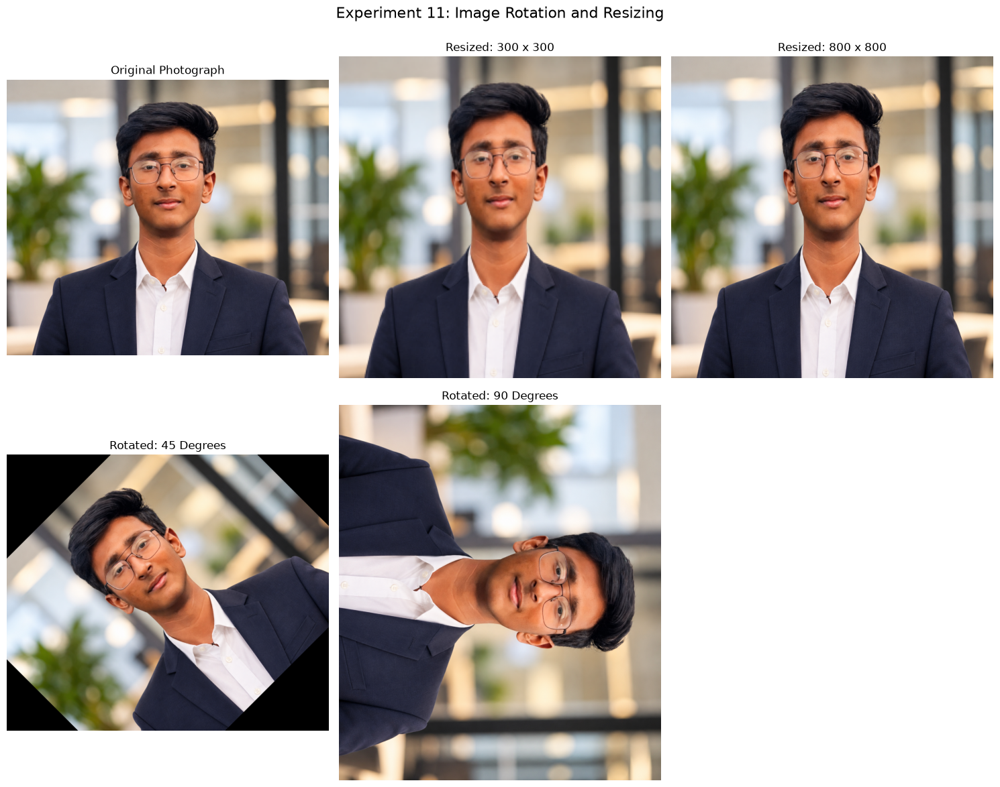

EXPERIMENT 11: IMAGE ROTATION AND RESIZING
---------------------------------------------
Original dimensions: (1161, 1354, 3)
Small resized dimensions: (300, 300, 3)
Large resized dimensions: (800, 800, 3)
45-degree rotation dimensions: (1161, 1354, 3)
90-degree rotation dimensions: (1354, 1161, 3)
Saved transformed images in: outputs/unit4
Image rotation and resizing completed successfully!


In [36]:
import os
import cv2
import matplotlib.pyplot as plt

# Step 1: Define paths
image_path = "data/images/original_photo.png"
output_dir = "outputs/unit4"

os.makedirs(output_dir, exist_ok=True)

# Step 2: Load the original photograph
original = cv2.imread(image_path)

if original is None:
    raise FileNotFoundError(f"Image not found: {image_path}")

height, width = original.shape[:2]

# Step 3: Resize the image
resized_small = cv2.resize(
    original,
    (300, 300),
    interpolation=cv2.INTER_AREA
)

resized_large = cv2.resize(
    original,
    (800, 800),
    interpolation=cv2.INTER_CUBIC
)

# Step 4: Rotate the image by 45 degrees
center = (width // 2, height // 2)

rotation_matrix = cv2.getRotationMatrix2D(
    center,
    45,
    1.0
)

rotated_45 = cv2.warpAffine(
    original,
    rotation_matrix,
    (width, height)
)

# Step 5: Rotate the image by 90 degrees
rotated_90 = cv2.rotate(
    original,
    cv2.ROTATE_90_CLOCKWISE
)

# Step 6: Save transformed images
cv2.imwrite(f"{output_dir}/03_resized_small.png", resized_small)
cv2.imwrite(f"{output_dir}/04_resized_large.png", resized_large)
cv2.imwrite(f"{output_dir}/05_rotated_45.png", rotated_45)
cv2.imwrite(f"{output_dir}/06_rotated_90.png", rotated_90)

# Step 7: Convert images to RGB for display
original_rgb = cv2.cvtColor(original, cv2.COLOR_BGR2RGB)
small_rgb = cv2.cvtColor(resized_small, cv2.COLOR_BGR2RGB)
large_rgb = cv2.cvtColor(resized_large, cv2.COLOR_BGR2RGB)
rotated_45_rgb = cv2.cvtColor(rotated_45, cv2.COLOR_BGR2RGB)
rotated_90_rgb = cv2.cvtColor(rotated_90, cv2.COLOR_BGR2RGB)

# Step 8: Display results
images = [
    ("Original Photograph", original_rgb),
    ("Resized: 300 x 300", small_rgb),
    ("Resized: 800 x 800", large_rgb),
    ("Rotated: 45 Degrees", rotated_45_rgb),
    ("Rotated: 90 Degrees", rotated_90_rgb)
]

plt.figure(figsize=(15, 12))

for index, (title, image) in enumerate(images, start=1):
    plt.subplot(2, 3, index)
    plt.imshow(image)
    plt.title(title)
    plt.axis("off")

plt.suptitle(
    "Experiment 11: Image Rotation and Resizing",
    fontsize=16
)

plt.tight_layout()
plt.show()

# Step 9: Display experiment details
print("EXPERIMENT 11: IMAGE ROTATION AND RESIZING")
print("-" * 45)
print("Original dimensions:", original.shape)
print("Small resized dimensions:", resized_small.shape)
print("Large resized dimensions:", resized_large.shape)
print("45-degree rotation dimensions:", rotated_45.shape)
print("90-degree rotation dimensions:", rotated_90.shape)
print("Saved transformed images in:", output_dir)
print("Image rotation and resizing completed successfully!")

### Observation

Resizing changed the dimensions of the photograph. The smaller image was reduced to 300 × 300 pixels, while the larger image was increased to 800 × 800 pixels. Rotation changed the orientation of the photograph by 45 and 90 degrees.

The 45-degree rotation retained the original canvas dimensions, which resulted in some corner regions being cropped. The 90-degree rotation changed the orientation and swapped the image's height and width.

### Result

Image resizing and rotation were successfully implemented using OpenCV. The original, resized, and rotated photographs were displayed, and the transformed images were saved for further use.

# UNIT 5: OBJECT DETECTION AND MOTION ESTIMATION

## Experiment 12: Object Detection Using the Viola–Jones Algorithm

### Aim
To detect faces in a photograph using the Viola–Jones object detection approach and a Haar Cascade classifier.

### Theory
The Viola–Jones framework is an object detection approach commonly used for face detection. It uses Haar-like features to represent image patterns and a cascade of classifiers to reject background regions efficiently.

The classifier evaluates candidate regions at multiple scales to identify regions that may contain faces.

OpenCV provides pretrained Haar Cascade classifiers that can be used to detect faces in photographs.

### Procedure
1. Load the original photograph.
2. Convert the photograph to grayscale.
3. Load a pretrained Haar Cascade face classifier.
4. Detect faces in the photograph.
5. Draw rectangles around detected faces.
6. Display and save the detection result.

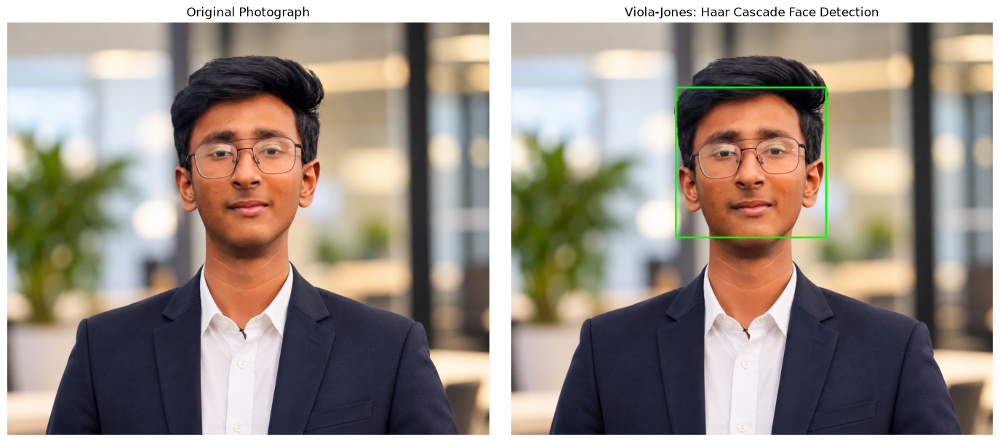

EXPERIMENT 12: HAAR CASCADE FACE DETECTION
---------------------------------------------
Image dimensions: (1161, 1354, 3)
Faces detected: 1
Classifier: haarcascade_frontalface_default.xml
Saved output: outputs/unit5/01_haar_face_detection.png
Face detection completed successfully!


In [2]:
import os
import cv2
import matplotlib.pyplot as plt

# Step 1: Define paths
image_path = "data/images/original_photo.png"
output_dir = "outputs/unit5"

os.makedirs(output_dir, exist_ok=True)

# Step 2: Load the original photograph
original = cv2.imread(image_path)

if original is None:
    raise FileNotFoundError(f"Image not found: {image_path}")

# Step 3: Convert the image to grayscale
gray = cv2.cvtColor(original, cv2.COLOR_BGR2GRAY)

# Step 4: Load the pretrained Haar Cascade classifier
cascade_path = (
    cv2.data.haarcascades
    + "haarcascade_frontalface_default.xml"
)

face_cascade = cv2.CascadeClassifier(cascade_path)

if face_cascade.empty():
    raise RuntimeError("Could not load the Haar Cascade classifier.")

# Step 5: Detect faces
faces = face_cascade.detectMultiScale(
    gray,
    scaleFactor=1.1,
    minNeighbors=5,
    minSize=(30, 30)
)

# Step 6: Draw rectangles around detected faces
detected_image = original.copy()

for (x, y, w, h) in faces:
    cv2.rectangle(
        detected_image,
        (x, y),
        (x + w, y + h),
        (0, 255, 0),
        3
    )

# Step 7: Save the detection result
output_path = f"{output_dir}/01_haar_face_detection.png"
cv2.imwrite(output_path, detected_image)

# Step 8: Convert images to RGB for display
original_rgb = cv2.cvtColor(original, cv2.COLOR_BGR2RGB)
detected_rgb = cv2.cvtColor(detected_image, cv2.COLOR_BGR2RGB)

# Step 9: Display the results
plt.figure(figsize=(14, 6))

plt.subplot(1, 2, 1)
plt.imshow(original_rgb)
plt.title("Original Photograph")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(detected_rgb)
plt.title("Viola-Jones: Haar Cascade Face Detection")
plt.axis("off")

plt.tight_layout()
plt.show()

# Step 10: Display experiment details
print("EXPERIMENT 12: HAAR CASCADE FACE DETECTION")
print("-" * 45)
print("Image dimensions:", original.shape)
print("Faces detected:", len(faces))
print("Classifier:", "haarcascade_frontalface_default.xml")
print("Saved output:", output_path)
print("Face detection completed successfully!")

In [41]:
%pip install opencv-python==4.11.0.86

   ---------------------------------------- 0.0/39.5 MB ? eta -:--:--
   - -------------------------------------- 1.3/39.5 MB 13.3 MB/s eta 0:00:03
   -- ------------------------------------- 2.6/39.5 MB 8.9 MB/s eta 0:00:05
   --- ------------------------------------ 3.7/39.5 MB 6.6 MB/s eta 0:00:06
   ---- ----------------------------------- 4.7/39.5 MB 6.2 MB/s eta 0:00:06
   ----- ---------------------------------- 5.5/39.5 MB 5.9 MB/s eta 0:00:06
   ----- ---------------------------------- 5.8/39.5 MB 5.5 MB/s eta 0:00:07
   ------ --------------------------------- 6.0/39.5 MB 4.9 MB/s eta 0:00:07
   ------ --------------------------------- 6.6/39.5 MB 4.0 MB/s eta 0:00:09
   ------ --------------------------------- 6.6/39.5 MB 4.0 MB/s eta 0:00:09
   ------ --------------------------------- 6.8/39.5 MB 3.5 MB/s eta 0:00:10
   ------- -------------------------------- 7.1/39.5 MB 3.1 MB/s eta 0:00:11
   ------- -------------------------------- 7.1/39.5 MB 3.1 MB/s eta 0:00:11
   --

In [1]:
import cv2

print("OpenCV version:", cv2.__version__)
print("CascadeClassifier available:", hasattr(cv2, "CascadeClassifier"))

OpenCV version: 4.11.0
CascadeClassifier available: True


## Experiment 13: Object Detection Using YOLO

### Aim
To detect and classify objects in a photograph using the YOLO (You Only Look Once) object detection algorithm.

### Theory
YOLO is a real-time object detection algorithm that identifies and classifies multiple objects in an image in a single inference pass.

A pretrained YOLO model predicts object locations using bounding boxes, assigns class labels, and estimates confidence scores for its detections.

In this experiment, a pretrained YOLO model will be used to detect objects in a photograph and visualize the results.

### Procedure
1. Load the original photograph.
2. Load a pretrained YOLO model.
3. Perform object detection on the photograph.
4. Retrieve the predicted bounding boxes, class labels, and confidence scores.
5. Display the detected objects.
6. Save the detection result.

In [4]:
%pip install ultralytics

Note: you may need to restart the kernel to use updated packages.


Creating new Ultralytics Settings v0.0.8 file  
View Ultralytics Settings with 'yolo settings' or at 'C:\Users\Tanay panchal\AppData\Roaming\Ultralytics\settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.


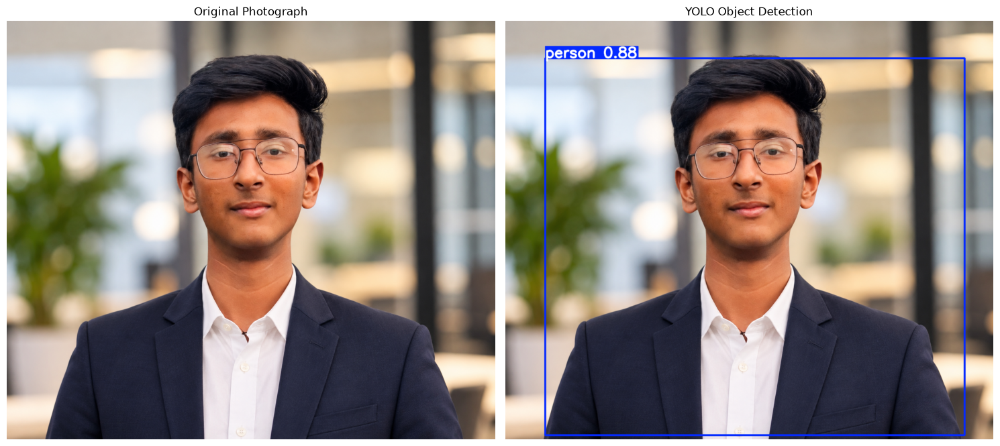

EXPERIMENT 13: YOLO OBJECT DETECTION
---------------------------------------------
Object: person | Confidence: 0.88
Total detections: 1
Saved output: outputs/unit5/02_yolo_object_detection.png
YOLO object detection completed!


In [1]:
import os
import cv2
import matplotlib.pyplot as plt
from ultralytics import YOLO

# Step 1: Define paths
image_path = "data/images/original_photo.png"
output_dir = "outputs/unit5"

os.makedirs(output_dir, exist_ok=True)

# Step 2: Load the original photograph
original = cv2.imread(image_path)

if original is None:
    raise FileNotFoundError(f"Image not found: {image_path}")

# Step 3: Load the pretrained YOLO model
model = YOLO("yolo11n.pt")

# Step 4: Perform object detection
results = model.predict(
    source=image_path,
    conf=0.25,
    verbose=False
)

# Step 5: Draw bounding boxes and labels
annotated_image = results[0].plot()

# Step 6: Save the result
output_path = f"{output_dir}/02_yolo_object_detection.png"
cv2.imwrite(output_path, annotated_image)

# Step 7: Display the images
original_rgb = cv2.cvtColor(original, cv2.COLOR_BGR2RGB)
annotated_rgb = cv2.cvtColor(annotated_image, cv2.COLOR_BGR2RGB)

plt.figure(figsize=(15, 7))

plt.subplot(1, 2, 1)
plt.imshow(original_rgb)
plt.title("Original Photograph")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(annotated_rgb)
plt.title("YOLO Object Detection")
plt.axis("off")

plt.tight_layout()
plt.show()

# Step 8: Display detection details
print("EXPERIMENT 13: YOLO OBJECT DETECTION")
print("-" * 45)

boxes = results[0].boxes

if boxes is not None and len(boxes) > 0:
    for box in boxes:
        class_id = int(box.cls[0])
        confidence = float(box.conf[0])
        class_name = model.names[class_id]

        print(
            f"Object: {class_name} | "
            f"Confidence: {confidence:.2f}"
        )
else:
    print("No objects detected.")

print("Total detections:", len(boxes) if boxes is not None else 0)
print("Saved output:", output_path)
print("YOLO object detection completed!")

### Observation

The pretrained YOLO model analyzed the photograph and predicted bounding boxes, class labels, and confidence scores for the detected objects.

Detection results depended on the objects visible in the photograph, the model's training categories, and the selected confidence threshold.

### Result

YOLO object detection was successfully implemented using the Ultralytics library. The detected objects were visualized using bounding boxes and labels, and the resulting image was saved.

## Experiment 14: Motion Estimation Using Frame Differencing

### Aim
To detect motion in a video by calculating the difference between consecutive frames.

### Theory
Frame differencing is a basic motion detection technique that compares consecutive video frames. Differences in pixel intensity can indicate movement between frames.

The method typically converts frames to grayscale, calculates their absolute difference, and applies a threshold to identify regions with significant changes.

Frame differencing is simple and computationally efficient, but it can be sensitive to noise, lighting changes, and camera movement.

### Procedure
1. Load a video recorded by the student.
2. Read consecutive video frames.
3. Convert the frames to grayscale.
4. Calculate the absolute difference between consecutive frames.
5. Apply thresholding to highlight motion.
6. Display and save the motion detection results.

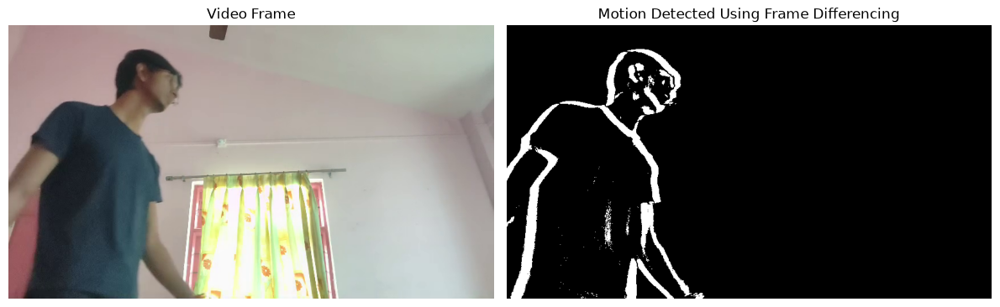

EXPERIMENT 14: FRAME DIFFERENCING
----------------------------------------
Video: data/videos/motion_video.mp4
Frames processed: 897
Motion threshold: 25
Saved motion mask: outputs/unit5/03_frame_differencing_result.png
Frame differencing completed successfully!


In [2]:
import os
import cv2
import matplotlib.pyplot as plt

# Step 1: Define paths
video_path = "data/videos/motion_video.mp4"
output_dir = "outputs/unit5"

os.makedirs(output_dir, exist_ok=True)

# Step 2: Open the video
cap = cv2.VideoCapture(video_path)

if not cap.isOpened():
    raise FileNotFoundError(f"Could not open video: {video_path}")

# Step 3: Read the first frame
ret, previous_frame = cap.read()

if not ret:
    cap.release()
    raise ValueError("Could not read the first frame of the video.")

previous_gray = cv2.cvtColor(previous_frame, cv2.COLOR_BGR2GRAY)

# Step 4: Prepare variables
frame_count = 0
motion_frames = []
motion_threshold = 25

# Step 5: Process consecutive frames
while True:
    ret, current_frame = cap.read()

    if not ret:
        break

    current_gray = cv2.cvtColor(current_frame, cv2.COLOR_BGR2GRAY)

    # Calculate the absolute difference
    frame_difference = cv2.absdiff(previous_gray, current_gray)

    # Apply thresholding to highlight motion
    _, motion_mask = cv2.threshold(
        frame_difference,
        motion_threshold,
        255,
        cv2.THRESH_BINARY
    )

    # Save a sample result every 30 processed frames
    if frame_count % 30 == 0:
        motion_frames.append(
            (current_frame.copy(), motion_mask.copy())
        )

    previous_gray = current_gray
    frame_count += 1

cap.release()

# Step 6: Check whether frames were processed
if not motion_frames:
    raise ValueError("No video frames were processed.")

# Step 7: Save the final sample
sample_frame, sample_mask = motion_frames[-1]

sample_path = f"{output_dir}/03_frame_differencing_result.png"

cv2.imwrite(sample_path, sample_mask)

# Step 8: Display the original sample and motion mask
sample_rgb = cv2.cvtColor(sample_frame, cv2.COLOR_BGR2RGB)

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(sample_rgb)
plt.title("Video Frame")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(sample_mask, cmap="gray")
plt.title("Motion Detected Using Frame Differencing")
plt.axis("off")

plt.tight_layout()
plt.show()

# Step 9: Display experiment details
print("EXPERIMENT 14: FRAME DIFFERENCING")
print("-" * 40)
print("Video:", video_path)
print("Frames processed:", frame_count)
print("Motion threshold:", motion_threshold)
print("Saved motion mask:", sample_path)
print("Frame differencing completed successfully!")

### Observation

Frame differencing was used to compare consecutive grayscale video frames. The absolute difference between frames highlighted regions where pixel intensities changed. Thresholding converted these differences into a binary motion mask.

The detected motion depended on the movement in the video, lighting conditions, camera stability, and the selected threshold value.

### Result

Motion estimation using frame differencing was successfully implemented using OpenCV. A sample video frame and its corresponding motion mask were displayed, and the motion mask was saved for analysis.

## Experiment 15: Motion Detection Using Gaussian Mixture Model (GMM)

### Aim
To detect moving objects in a video using Gaussian Mixture Model (GMM) background subtraction.

### Theory
Background subtraction is a computer vision technique used to separate moving foreground objects from the background of a video.

The Gaussian Mixture Model (GMM) represents background pixels using a mixture of Gaussian distributions. OpenCV provides the MOG2 background subtraction algorithm, which adapts to gradual background changes and classifies pixels as foreground or background.

The resulting foreground mask highlights regions that differ from the estimated background. Shadows may also be detected depending on the algorithm's settings.

### Procedure
1. Load the recorded video.
2. Initialize the MOG2 background subtractor.
3. Read the video frames sequentially.
4. Apply background subtraction to each frame.
5. Display the original frame and foreground mask.
6. Save a sample foreground mask for analysis.

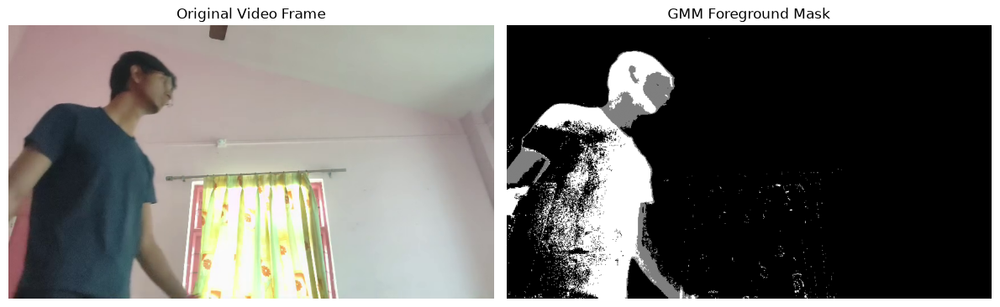

EXPERIMENT 15: GMM BACKGROUND SUBTRACTION
---------------------------------------------
Video: data/videos/motion_video.mp4
Frames processed: 898
History: 500
Variance threshold: 25
Shadow detection: True
Saved output: outputs/unit5/04_gmm_background_subtraction.png
GMM background subtraction completed successfully!


In [3]:
import os
import cv2
import matplotlib.pyplot as plt

# Step 1: Define paths
video_path = "data/videos/motion_video.mp4"
output_dir = "outputs/unit5"

os.makedirs(output_dir, exist_ok=True)

# Step 2: Open the video
cap = cv2.VideoCapture(video_path)

if not cap.isOpened():
    raise FileNotFoundError(f"Could not open video: {video_path}")

# Step 3: Initialize the GMM background subtractor
background_subtractor = cv2.createBackgroundSubtractorMOG2(
    history=500,
    varThreshold=25,
    detectShadows=True
)

# Step 4: Prepare variables
frame_count = 0
sample_results = []
sample_interval = 30

# Step 5: Process video frames
while True:
    ret, frame = cap.read()

    if not ret:
        break

    # Apply GMM background subtraction
    foreground_mask = background_subtractor.apply(frame)

    # Store sample results
    if frame_count % sample_interval == 0:
        sample_results.append(
            (frame.copy(), foreground_mask.copy())
        )

    frame_count += 1

cap.release()

# Step 6: Check the results
if not sample_results:
    raise ValueError("No frames were processed. Check the video file.")

# Step 7: Select and save a sample result
sample_frame, sample_mask = sample_results[-1]

output_path = f"{output_dir}/04_gmm_background_subtraction.png"

cv2.imwrite(output_path, sample_mask)

# Step 8: Convert the frame to RGB for display
sample_rgb = cv2.cvtColor(sample_frame, cv2.COLOR_BGR2RGB)

# Step 9: Display results
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(sample_rgb)
plt.title("Original Video Frame")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(sample_mask, cmap="gray")
plt.title("GMM Foreground Mask")
plt.axis("off")

plt.tight_layout()
plt.show()

# Step 10: Display experiment details
print("EXPERIMENT 15: GMM BACKGROUND SUBTRACTION")
print("-" * 45)
print("Video:", video_path)
print("Frames processed:", frame_count)
print("History:", 500)
print("Variance threshold:", 25)
print("Shadow detection:", True)
print("Saved output:", output_path)
print("GMM background subtraction completed successfully!")

### Observation

The MOG2 background subtractor processed successive video frames and estimated the background using a Gaussian mixture model. The resulting foreground mask highlighted regions that differed from the estimated background.

The quality of motion detection depended on the video content, camera stability, lighting conditions, and background subtraction parameters. Some shadows or background changes could also appear in the foreground mask.

### Result

GMM-based background subtraction was successfully implemented using OpenCV's MOG2 algorithm. The original video frame and corresponding foreground mask were displayed, and the mask was saved for analysis.

## Experiment 16: Motion Estimation Using Lucas–Kanade Optical Flow

### Aim
To estimate the movement of feature points between consecutive video frames using the Lucas–Kanade optical flow method.

### Theory
Optical flow estimates the apparent motion of pixels or selected feature points between consecutive video frames.

The Lucas–Kanade method is a sparse optical flow technique that tracks selected feature points across frames. It estimates the displacement of these points by assuming that their appearance remains approximately consistent over a short time interval.

In this experiment, Shi–Tomasi corner detection is used to select trackable feature points, and the Lucas–Kanade method tracks them across consecutive video frames.

### Procedure
1. Load the recorded video.
2. Read the first frame and convert it to grayscale.
3. Detect suitable feature points using Shi–Tomasi corner detection.
4. Read the next video frame.
5. Track the feature points using Lucas–Kanade optical flow.
6. Draw motion tracks and feature points on the video frame.
7. Display and save the motion estimation result.

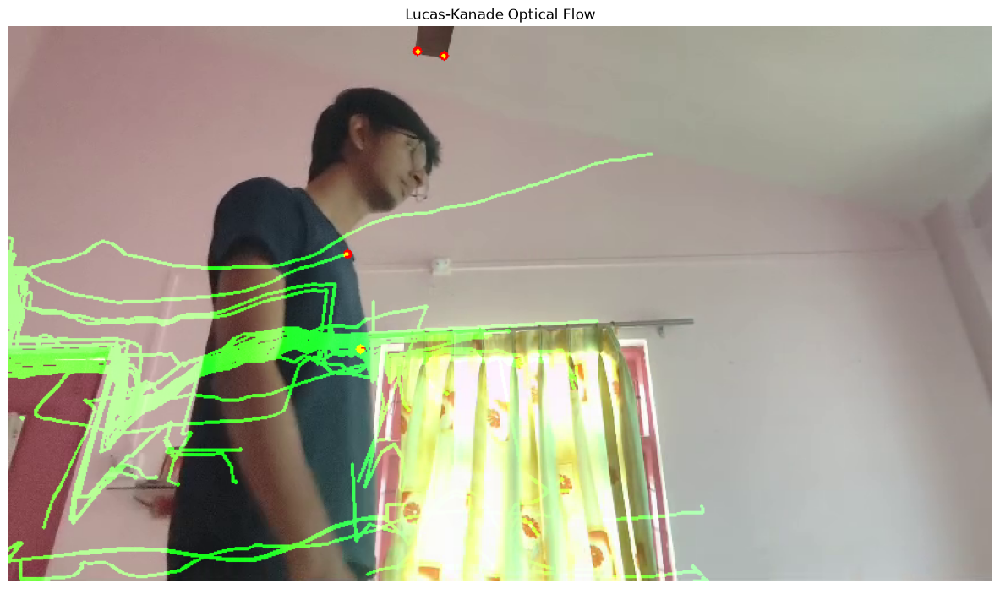

EXPERIMENT 16: LUCAS-KANADE OPTICAL FLOW
---------------------------------------------
Video: data/videos/motion_video.mp4
Frames processed: 150
Tracked points: 4
Saved output: outputs/unit5\05_lucas_kanade_optical_flow.png
Lucas-Kanade optical flow completed successfully!


In [6]:
import os
import cv2
import numpy as np
import matplotlib.pyplot as plt

# ============================================================
# EXPERIMENT 16: LUCAS-KANADE OPTICAL FLOW
# ============================================================

# Step 1: Define paths
video_path = "data/videos/motion_video.mp4"
output_dir = "outputs/unit5"

os.makedirs(output_dir, exist_ok=True)

output_path = os.path.join(
    output_dir,
    "05_lucas_kanade_optical_flow.png"
)

# Step 2: Open the video
cap = cv2.VideoCapture(video_path)

if not cap.isOpened():
    raise FileNotFoundError(
        f"Could not open video: {video_path}"
    )

# Step 3: Read the first frame
ret, old_frame = cap.read()

if not ret:
    cap.release()
    raise ValueError("Could not read the first video frame.")

old_gray = cv2.cvtColor(old_frame, cv2.COLOR_BGR2GRAY)

# Step 4: Detect feature points
feature_params = {
    "maxCorners": 150,
    "qualityLevel": 0.2,
    "minDistance": 10,
    "blockSize": 7
}

p0 = cv2.goodFeaturesToTrack(
    old_gray,
    mask=None,
    **feature_params
)

if p0 is None or len(p0) == 0:
    cap.release()
    raise RuntimeError("No feature points detected.")

# Step 5: Configure Lucas-Kanade optical flow
lk_params = {
    "winSize": (21, 21),
    "maxLevel": 3,
    "criteria": (
        cv2.TERM_CRITERIA_EPS | cv2.TERM_CRITERIA_COUNT,
        20,
        0.01
    )
}

# Create a mask for motion trails
track_mask = np.zeros_like(old_frame)

frame_count = 0
tracked_points_count = len(p0)

# Process a limited sequence of consecutive frames
max_frames = 150

while frame_count < max_frames:

    ret, frame = cap.read()

    if not ret:
        break

    frame_gray = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)

    # Calculate optical flow
    p1, status, error = cv2.calcOpticalFlowPyrLK(
        old_gray,
        frame_gray,
        p0,
        None,
        **lk_params
    )

    if p1 is None or status is None:
        break

    # Select successfully tracked points
    good_new = p1[status.ravel() == 1]
    good_old = p0[status.ravel() == 1]

    if len(good_new) == 0:
        break

    # Draw motion trails
    for new_point, old_point in zip(good_new, good_old):

        x_new, y_new = new_point.ravel().astype(int)
        x_old, y_old = old_point.ravel().astype(int)

        cv2.line(
            track_mask,
            (x_old, y_old),
            (x_new, y_new),
            (0, 255, 0),
            2
        )

        cv2.circle(
            frame,
            (x_new, y_new),
            4,
            (0, 0, 255),
            -1
        )

    # Combine current frame and motion trails
    output_frame = cv2.add(frame, track_mask)

    # Update feature points and previous frame
    p0 = good_new.reshape(-1, 1, 2)
    old_gray = frame_gray.copy()

    tracked_points_count = len(good_new)
    frame_count += 1

cap.release()

# Step 6: Validate processing
if frame_count == 0:
    raise RuntimeError(
        "No points were tracked. Try adjusting the parameters."
    )

# Step 7: Save the result
cv2.imwrite(output_path, output_frame)

# Step 8: Display the result
output_rgb = cv2.cvtColor(
    output_frame,
    cv2.COLOR_BGR2RGB
)

plt.figure(figsize=(12, 7))
plt.imshow(output_rgb)
plt.title("Lucas-Kanade Optical Flow")
plt.axis("off")
plt.tight_layout()
plt.show()

# Step 9: Display experiment details
print("EXPERIMENT 16: LUCAS-KANADE OPTICAL FLOW")
print("-" * 45)
print("Video:", video_path)
print("Frames processed:", frame_count)
print("Tracked points:", tracked_points_count)
print("Saved output:", output_path)
print("Lucas-Kanade optical flow completed successfully!")

### Observation

The Lucas-Kanade optical flow method was used to track feature points between consecutive video frames. Green lines represent the estimated movement of tracked points, while red circles indicate their locations in the processed frame.

Tracking quality depended on feature visibility, movement between frames, lighting conditions, and video stability.

### Result

Lucas-Kanade optical flow was successfully implemented using OpenCV. Feature points were tracked across consecutive video frames, and the resulting motion visualization was displayed and saved for analysis.